# BlindAssist — ML Analysis

YOLOv8n, running on the CPU of an ordinary laptop, drives a real-time
direction-and-distance assistant for blind users. This notebook loads the
results of three measured runs and walks through them:

| Section | Source of the numbers |
|---|---|
| 1. Detection quality (COCO) | `scripts/evaluate.py` → `Evidence/eval_metrics.json` |
| 2. Per-class AP | `scripts/evaluate.py` → `Evidence/eval_per_class.json` |
| 3. Detection examples + confusion matrix | `Evidence/eval/` |
| 4. Inference speed | `scripts/benchmark.py` → `Evidence/benchmark.json` |
| 5. Direction & distance accuracy | `scripts/evaluate_position.py` → `Evidence/position_accuracy.json` |
| 6. Interpretation | composed from the values above |

Every figure below is read from those files at run time, so the notebook cannot
report a number that was not actually produced on this machine.


## 0. Setup


In [1]:
from pathlib import Path
import json
import sys

# Windows consoles default to cp1252, which cannot encode the arrows and dashes
# used in the reports below. Force UTF-8 so printing never raises here.
for _stream in (sys.stdout, sys.stderr):
    try:
        _stream.reconfigure(encoding="utf-8", errors="replace")
    except Exception:
        pass

import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Markdown, Image as IPyImage, display

# The notebook sits at the project root. Walk up until Evidence/ is found so it
# also works if it is executed from a different working directory.
ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / "Evidence").exists():
    ROOT = ROOT.parent
EVIDENCE = ROOT / "Evidence"
assert EVIDENCE.exists(), f"Evidence/ not found starting from {Path.cwd()}"

def load(name):
    return json.loads((EVIDENCE / name).read_text(encoding="utf-8"))

def md_table(headers, rows):
    """Render rows as a GitHub-flavoured markdown table."""
    sep = "|" + "|".join("-" * max(3, len(str(h))) for h in headers) + "|"
    lines = ["|" + "|".join(f" {h} " for h in headers) + "|", sep]
    for r in rows:
        lines.append("|" + "|".join(f" {c} " for c in r) + "|")
    return "\n".join(lines)

metrics     = load("eval_metrics.json")
per_class   = load("eval_per_class.json")
bench       = load("benchmark.json")
position    = load("position_accuracy.json")

print("loaded:", metrics["config"]["data"], "|",
      len(per_class), "classes with AP |",
      len(bench["results"]), "benchmark sizes |",
      position["totals"]["expected"], "annotated objects")


loaded: coco128.yaml | 71 classes with AP | 2 benchmark sizes | 38 annotated objects


## 1. Detection quality on a COCO subset

Evaluated with `ultralytics val` on **coco128** — 128 images sampled from COCO
val2017, downloaded once and cached locally. `conf=0.001` is used because mAP
must consider *every* prediction, not only the confident ones the app would
actually announce (the app itself runs at `conf=0.45`).


In [2]:
o   = metrics["overall"]
cfg = metrics["config"]
hw  = metrics["hardware"]

display(Markdown("### Run configuration\n\n" + md_table(
    ["Item", "Value"],
    [["Model", f"`{cfg['model']}` (COCO-pretrained, no fine-tuning)"],
     ["Dataset", f"`{cfg['data']}` — 128 images from COCO val2017"],
     ["Input size", f"{cfg['imgsz']} px"],
     ["Confidence threshold", f"{cfg['conf']} (standard for mAP)"],
     ["IoU / NMS threshold", f"{cfg['iou']}"],
     ["CPU", hw["cpu"]],
     ["GPU", hw["gpu"]],
     ["torch device", hw["torch_device"]],
     ["Wall time", f"{metrics['wall_seconds']:.1f} s"]])))

display(Markdown("### Headline metrics\n\n" + md_table(
    ["Metric", "Value"],
    [["Precision (P)", f"**{o['precision']:.4f}**"],
     ["Recall (R)", f"**{o['recall']:.4f}**"],
     ["mAP@0.5", f"**{o['map50']:.4f}**"],
     ["mAP@0.5:0.95", f"**{o['map5095']:.4f}**"],
     ["Classes that occur in this subset",
      f"{o['classes_evaluated']} of {o['classes_in_model']}"]])))


### Run configuration

| Item | Value |
|----|-----|
| Model | `BlindAssist_Project\assets\yolov8n.pt` (COCO-pretrained, no fine-tuning) |
| Dataset | `coco128.yaml` — 128 images from COCO val2017 |
| Input size | 640 px |
| Confidence threshold | 0.001 (standard for mAP) |
| IoU / NMS threshold | 0.6 |
| CPU | Intel(R) Core(TM) i5-6300U CPU @ 2.40GHz |
| GPU | Intel(R) HD Graphics 520 (not CUDA-capable; torch runs on CPU) |
| torch device | cpu |
| Wall time | 57.0 s |

### Headline metrics

| Metric | Value |
|------|-----|
| Precision (P) | **0.6498** |
| Recall (R) | **0.5420** |
| mAP@0.5 | **0.6124** |
| mAP@0.5:0.95 | **0.4453** |
| Classes that occur in this subset | 71 of 80 |

## 2. Per-class AP — the 10 most common classes

Averaged metrics hide which classes actually work. Below are the ten classes
with the most ground-truth instances in this subset, ordered by how often they
appear. `AP@0.5` is lenient about box placement; `AP@0.5:0.95` averages over
IoU thresholds 0.05…0.95 and is much harder for small objects.


| Class | GT instances | P | R | AP@0.5 | AP@0.5:0.95 |
|-----|------------|---|---|------|-----------|
| person | 254 | 0.820 | 0.681 | 0.770 | 0.529 |
| car | 46 | 0.799 | 0.217 | 0.264 | 0.162 |
| cup | 36 | 0.595 | 0.286 | 0.408 | 0.283 |
| chair | 35 | 0.527 | 0.514 | 0.464 | 0.237 |
| book | 29 | 0.602 | 0.103 | 0.393 | 0.192 |
| bowl | 28 | 0.667 | 0.643 | 0.634 | 0.482 |
| carrot | 24 | 0.684 | 0.458 | 0.619 | 0.383 |
| spoon | 22 | 0.701 | 0.215 | 0.352 | 0.201 |
| teddy bear | 21 | 0.891 | 0.389 | 0.635 | 0.408 |
| handbag | 19 | 0.407 | 0.053 | 0.162 | 0.085 |

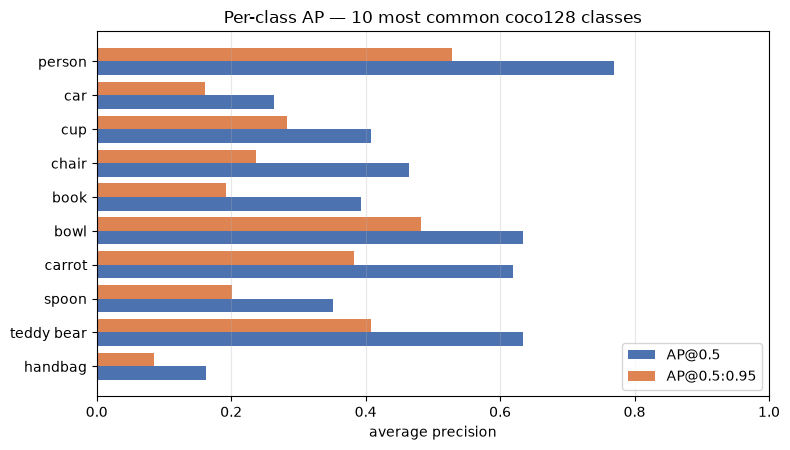

### Weakest classes

| Class | GT instances | AP@0.5 | AP@0.5:0.95 |
|-----|------------|------|-----------|
| mouse | 2 | 0.045 | 0.004 |
| cell phone | 8 | 0.050 | 0.034 |
| handbag | 19 | 0.162 | 0.085 |
| banana | 1 | 0.166 | 0.047 |
| sink | 6 | 0.184 | 0.128 |

In [3]:
top = sorted(per_class, key=lambda c: (-c["instances"], -c["ap50"]))[:10]

display(Markdown(md_table(
    ["Class", "GT instances", "P", "R", "AP@0.5", "AP@0.5:0.95"],
    [[c["name"], c["instances"],
      "n/a" if c["precision"] is None else f"{c['precision']:.3f}",
      "n/a" if c["recall"]  is None else f"{c['recall']:.3f}",
      f"{c['ap50']:.3f}", f"{c['ap5095']:.3f}"] for c in top])))

fig, ax = plt.subplots(figsize=(8, 4.6))
y   = list(range(len(top)))
lab = [c["name"] for c in top]
ax.barh([i + 0.20 for i in y], [c["ap50"]    for c in top],
        height=0.40, color="#4C72B0", label="AP@0.5")
ax.barh([i - 0.20 for i in y], [c["ap5095"]  for c in top],
        height=0.40, color="#DD8452", label="AP@0.5:0.95")
ax.set_yticks(y); ax.set_yticklabels(lab); ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("average precision")
ax.set_title("Per-class AP — 10 most common coco128 classes")
ax.legend(loc="lower right"); ax.grid(axis="x", alpha=0.3)
fig.tight_layout(); plt.show()

worst = sorted(per_class, key=lambda c: c["ap50"])[:5]
display(Markdown("### Weakest classes\n\n" + md_table(
    ["Class", "GT instances", "AP@0.5", "AP@0.5:0.95"],
    [[c["name"], c["instances"], f"{c['ap50']:.3f}", f"{c['ap5095']:.3f}"]
     for c in worst])))


## 3. Detection examples and confusion matrix

Ultralytics renders one validation batch twice — once with the ground-truth
boxes, once with the model's own predictions — on identical images. Comparing
them by eye shows what the tables cannot: *how* the model fails.


**Ground-truth labels:**

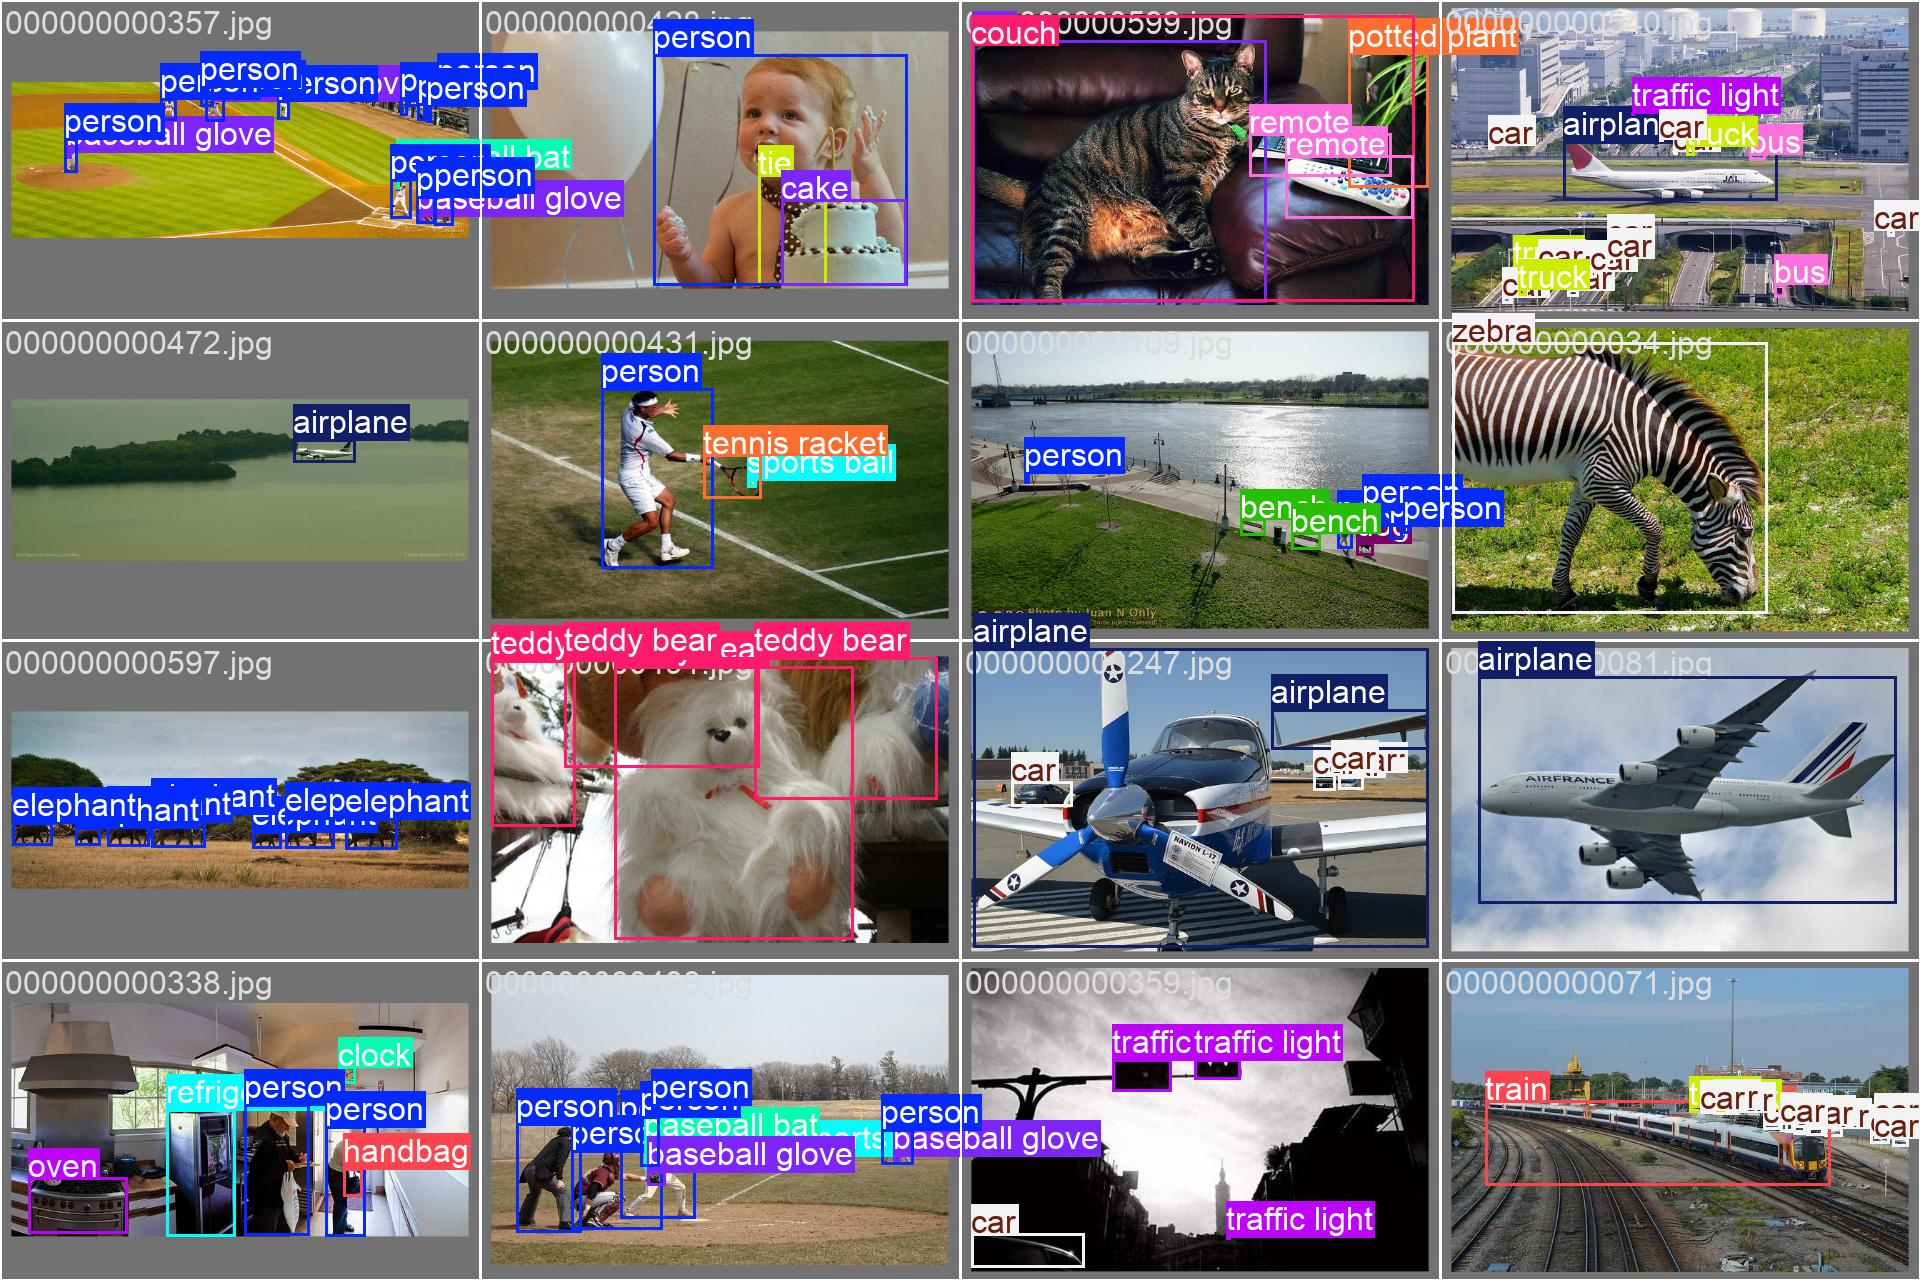

**YOLOv8n predictions on the same batch:**

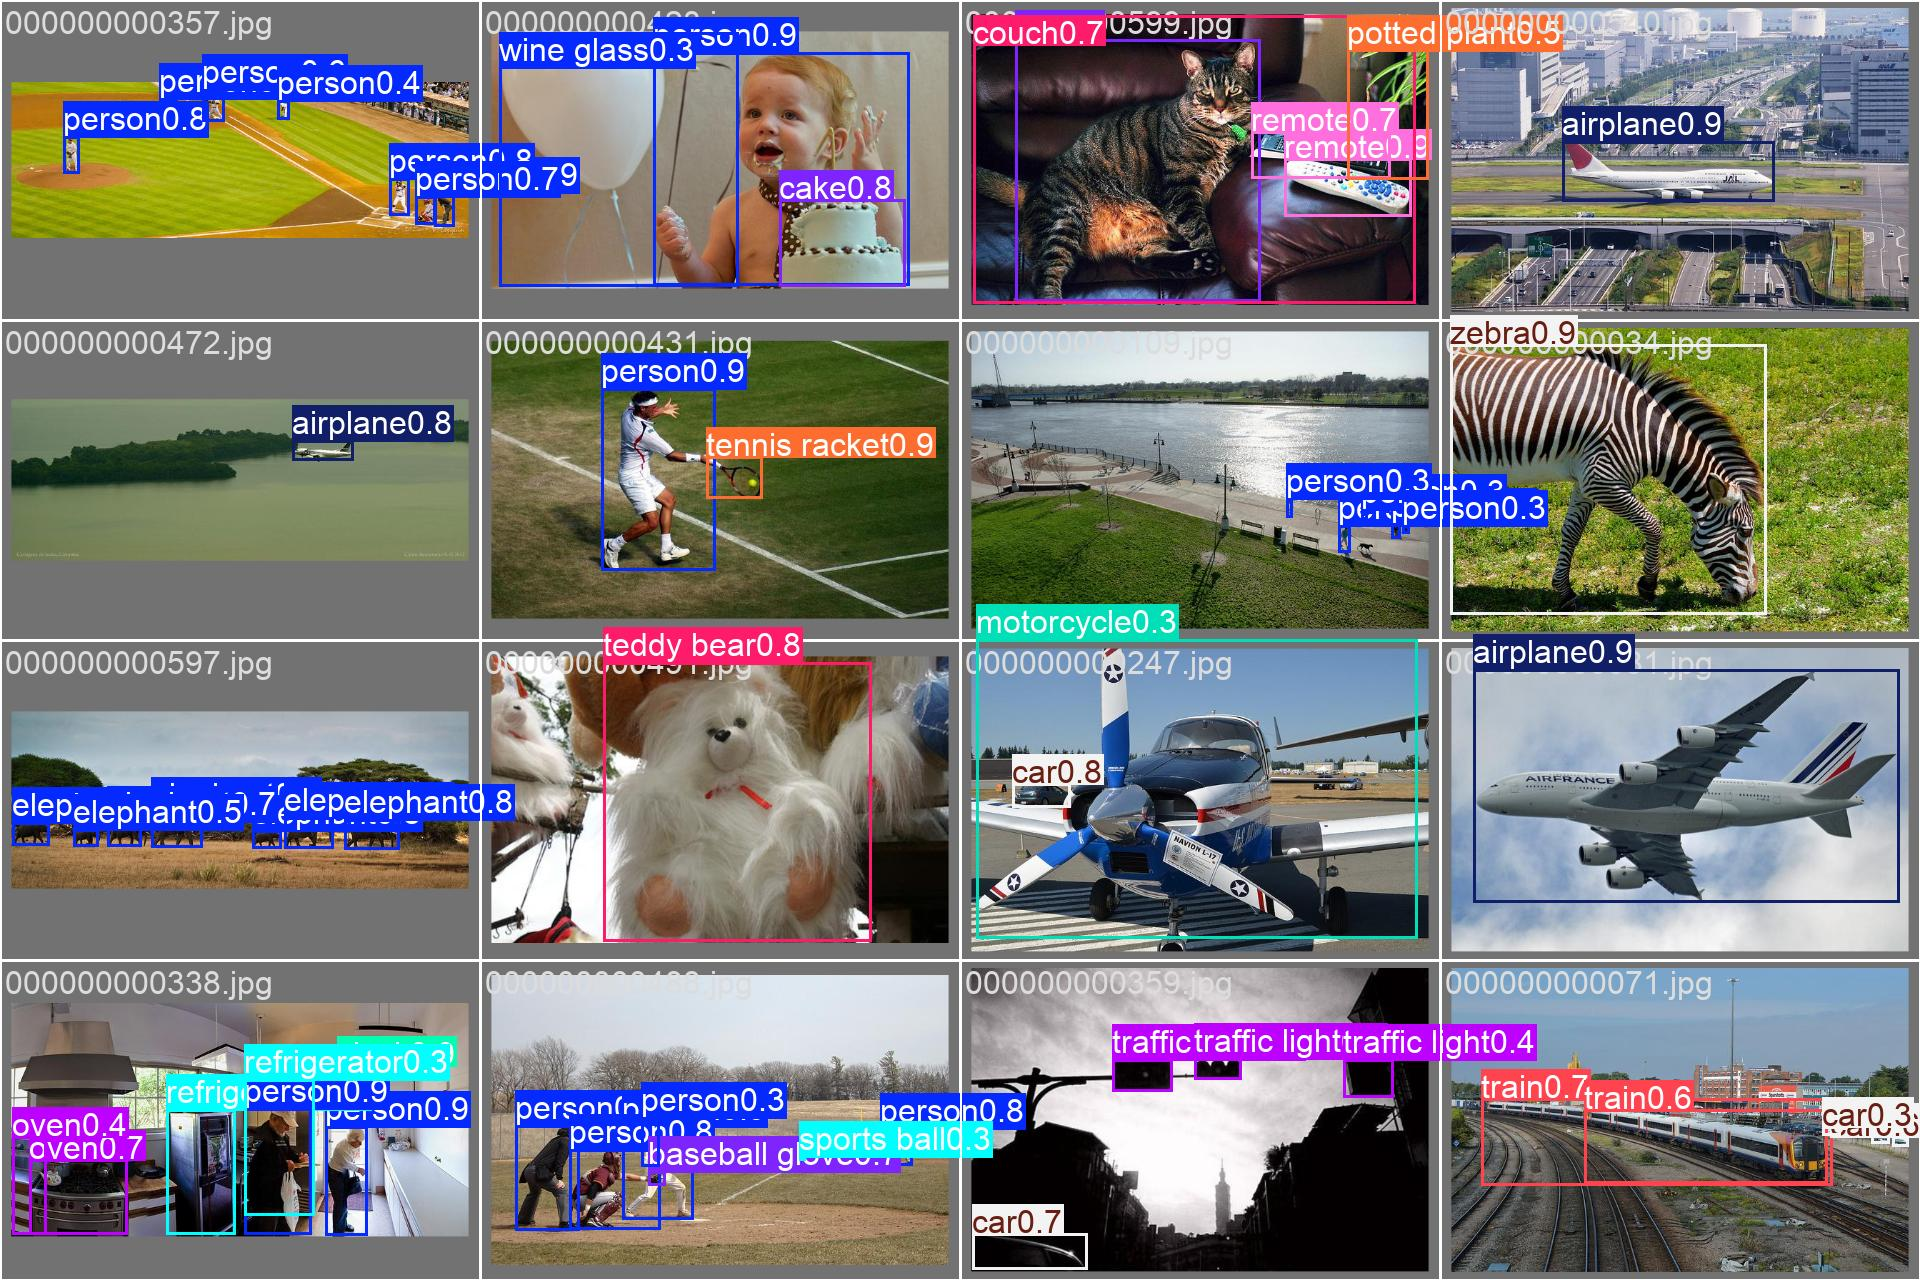

In [4]:
display(Markdown("**Ground-truth labels:**"))
display(IPyImage(str(EVIDENCE / "eval" / "val_batch0_labels.jpg"), width=540))
display(Markdown("**YOLOv8n predictions on the same batch:**"))
display(IPyImage(str(EVIDENCE / "eval" / "val_batch0_pred.jpg"), width=540))


**Normalised confusion matrix.** Rows are ground truth, columns are the prediction; the final row/column is *missed* / *false alarm*. The diagonal is what we want, and the right-hand column is the recall loss.

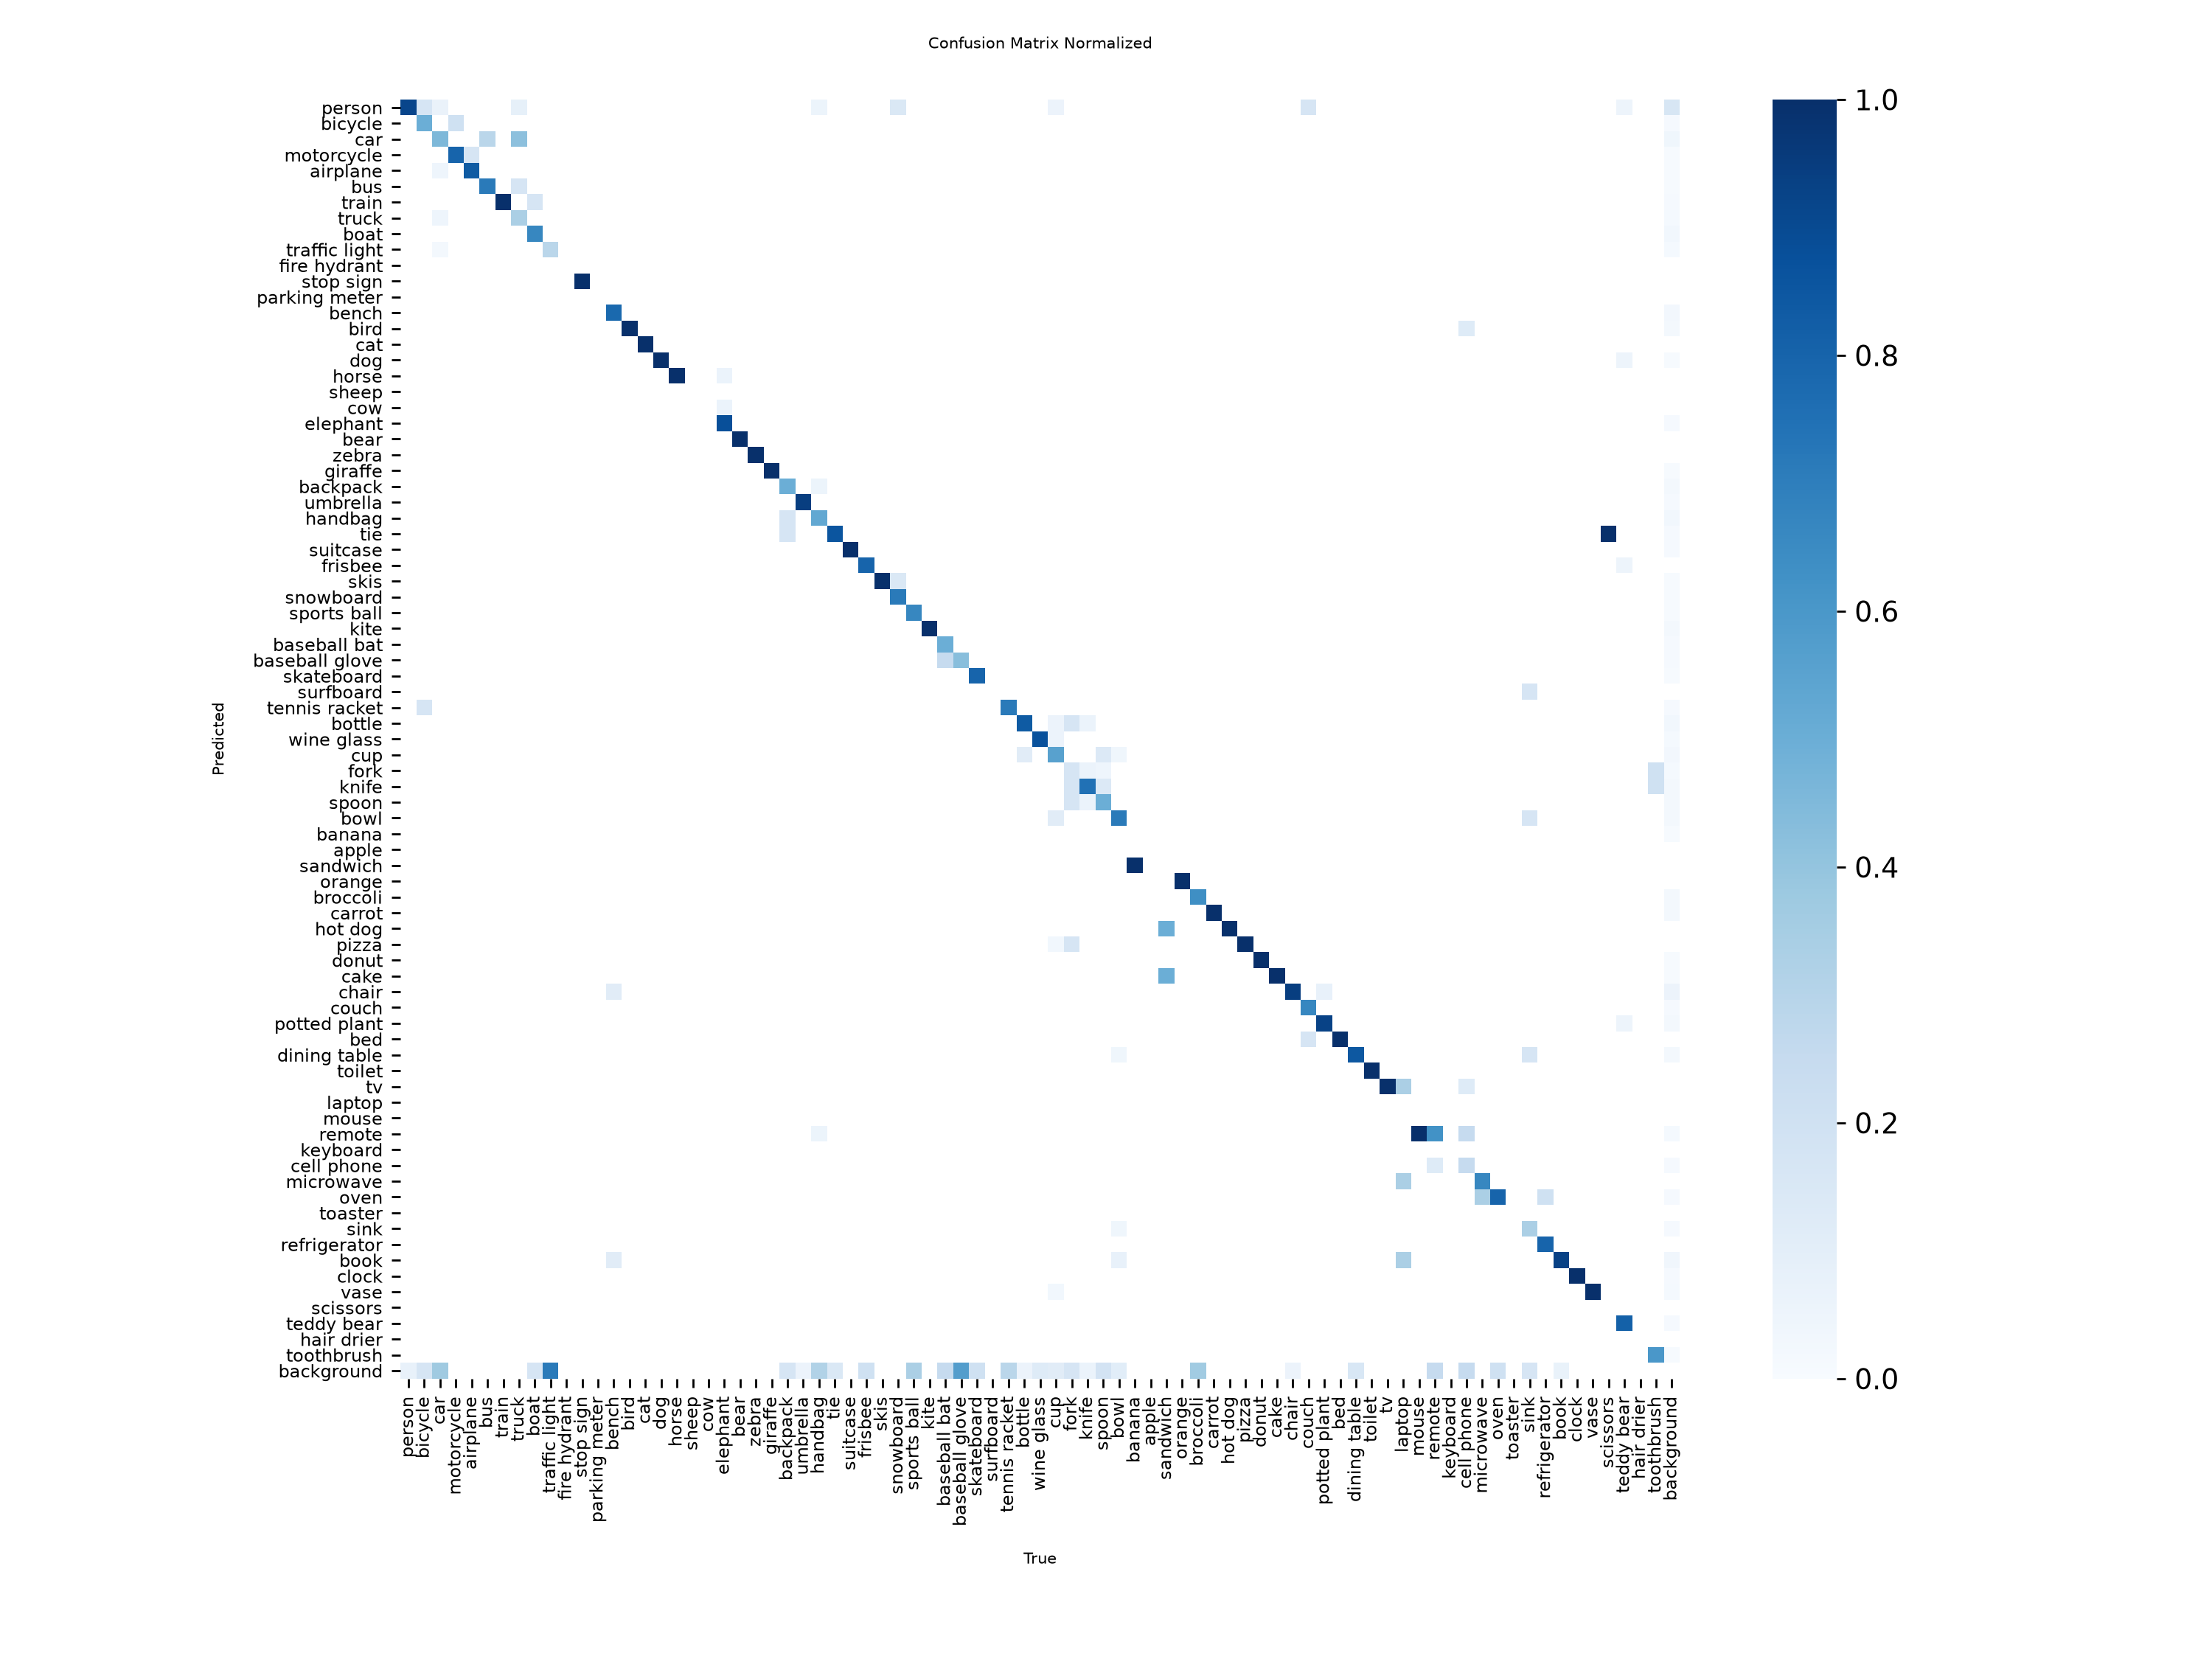

In [5]:
display(Markdown(
    "**Normalised confusion matrix.** Rows are ground truth, columns are the "
    "prediction; the final row/column is *missed* / *false alarm*. The diagonal "
    "is what we want, and the right-hand column is the recall loss."))
display(IPyImage(str(EVIDENCE / "eval" / "confusion_matrix_normalized.png"),
                 width=620))


## 4. Inference speed on this machine

100 frames per input size, batch size 1, measured end-to-end around
`model.predict()` so letterboxing, NMS and Python call overhead are all
included. This is the number that decides whether the live video stays smooth.


| Input size | Avg ms | Median | Min | Max | Stdev | FPS |
|----------|------|------|---|---|-----|---|
| 320 px | **75.6** | 67.5 | 47.7 | 150.9 | 20.1 | **13.2** |
| 640 px | **148.0** | 145.0 | 119.2 | 253.0 | 19.0 | **6.8** |

### Stage breakdown (mean ms per image)

| Input size | Preprocess | Inference | Postprocess |
|----------|----------|---------|-----------|
| 320 px | 1.83 | 71.16 | 1.93 |
| 640 px | 3.41 | 141.63 | 2.01 |

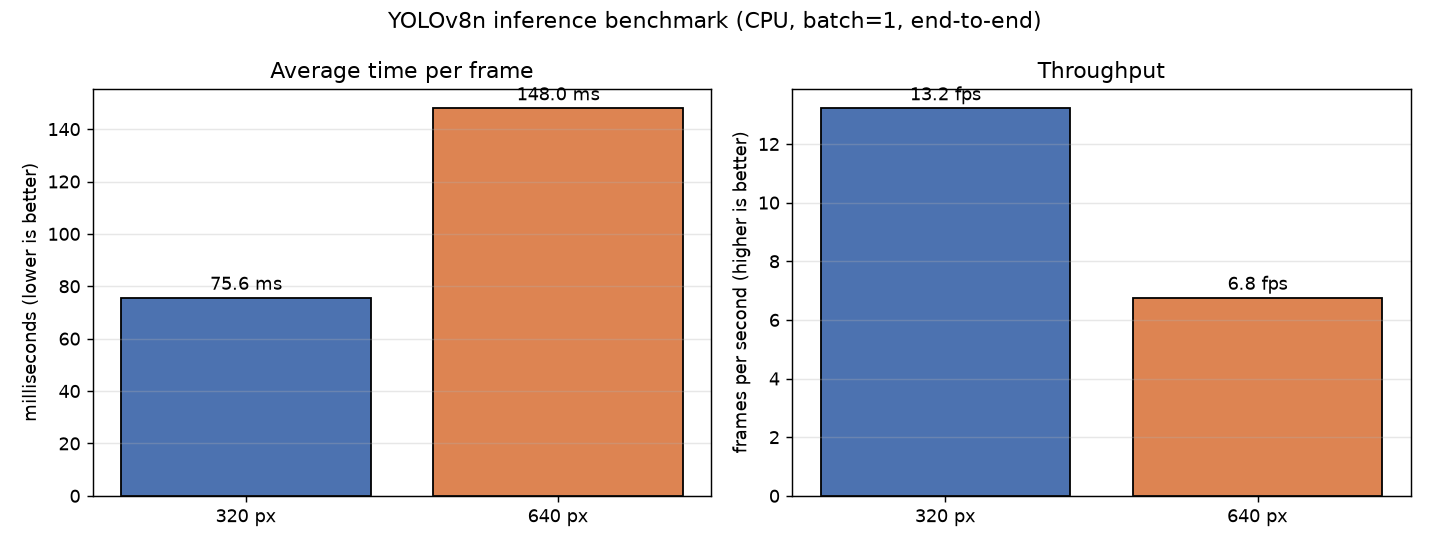

In [6]:
display(Markdown(md_table(
    ["Input size", "Avg ms", "Median", "Min", "Max", "Stdev", "FPS"],
    [[f"{r['imgsz']} px", f"**{r['avg_ms']:.1f}**", f"{r['median_ms']:.1f}",
      f"{r['min_ms']:.1f}", f"{r['max_ms']:.1f}", f"{r['stdev_ms']:.1f}",
      f"**{r['fps']:.1f}**"] for r in bench["results"]])))

display(Markdown("### Stage breakdown (mean ms per image)\n\n" + md_table(
    ["Input size", "Preprocess", "Inference", "Postprocess"],
    [[f"{r['imgsz']} px", f"{r['stages'].get('preprocess', 0):.2f}",
      f"{r['stages'].get('inference', 0):.2f}",
      f"{r['stages'].get('postprocess', 0):.2f}"]
     for r in bench["results"]])))

display(IPyImage(str(EVIDENCE / "benchmark.png"), width=660))


## 5. Direction and distance accuracy

Ten images (7 live webcam frames + 3 photos) were annotated **by hand**: for
each object a human recorded its approximate centre-x and where they perceive
it to be. Then the app's own `Detector` → `Positioner` ran on those images and
compared.

> **Important:** there is no depth sensor in this project, so "distance" is only
> a bounding-box-area heuristic. The ground truth for it is a human judging
> apparent size — this measures self-consistency of the heuristic, **not** metres.


In [7]:
t = position["totals"]
d = t["detected"]
display(Markdown(md_table(
    ["Measure", "Count", "Rate"],
    [["Objects expected", t["expected"], "—"],
     ["Correctly detected", t["detected"], f"**{d / t['expected']:.1%}**"],
     ["Direction correct (of those detected)", t["direction_correct"],
      f"**{t['direction_correct'] / d:.1%}**"],
     ["Distance band correct (of those detected)", t["band_correct"],
      f"**{t['band_correct'] / d:.1%}**"],
     ["Both correct (end-to-end over all)", t["both_correct"],
      f"**{t['both_correct'] / t['expected']:.1%}**"]])))

rows = []
for im in position["images"]:
    rr = im["rows"]
    rows.append([im["image"], len(rr),
                 sum(1 for r in rr if r["detected"]),
                 sum(1 for r in rr if r.get("direction_ok")),
                 sum(1 for r in rr if r.get("band_ok"))])
display(Markdown("\n### Per image\n\n" + md_table(
    ["Image", "Expected", "Found", "Direction OK", "Band OK"], rows)))

misses = [(i["image"], r["label"]) for i in position["images"]
          for r in i["rows"] if not r["detected"]]
display(Markdown(f"**Missed objects ({len(misses)}):** " +
                 (", ".join(f"`{f}` {lb}" for f, lb in misses) or "none")))


| Measure | Count | Rate |
|-------|-----|----|
| Objects expected | 38 | — |
| Correctly detected | 27 | **71.1%** |
| Direction correct (of those detected) | 26 | **96.3%** |
| Distance band correct (of those detected) | 27 | **100.0%** |
| Both correct (end-to-end over all) | 26 | **68.4%** |


### Per image

| Image | Expected | Found | Direction OK | Band OK |
|-----|--------|-----|------------|-------|
| cam_01.jpg | 3 | 2 | 1 | 2 |
| cam_02.jpg | 3 | 2 | 2 | 2 |
| cam_03.jpg | 3 | 2 | 2 | 2 |
| cam_04.jpg | 3 | 2 | 2 | 2 |
| cam_05.jpg | 3 | 2 | 2 | 2 |
| cam_06.jpg | 3 | 2 | 2 | 2 |
| cam_07.jpg | 3 | 2 | 2 | 2 |
| sample_person.jpg | 5 | 4 | 4 | 4 |
| sample_chair.jpg | 7 | 4 | 4 | 4 |
| sample_bottle.jpg | 5 | 5 | 5 | 5 |

**Missed objects (11):** `cam_01.jpg` person, `cam_02.jpg` person, `cam_03.jpg` person, `cam_04.jpg` person, `cam_05.jpg` person, `cam_06.jpg` person, `cam_07.jpg` person, `sample_person.jpg` person, `sample_chair.jpg` dining table, `sample_chair.jpg` potted plant, `sample_chair.jpg` potted plant

**What the detector actually saw.** Each box is labelled `class confidence zone/band` — the same words the app speaks.

*cam_01.jpg*

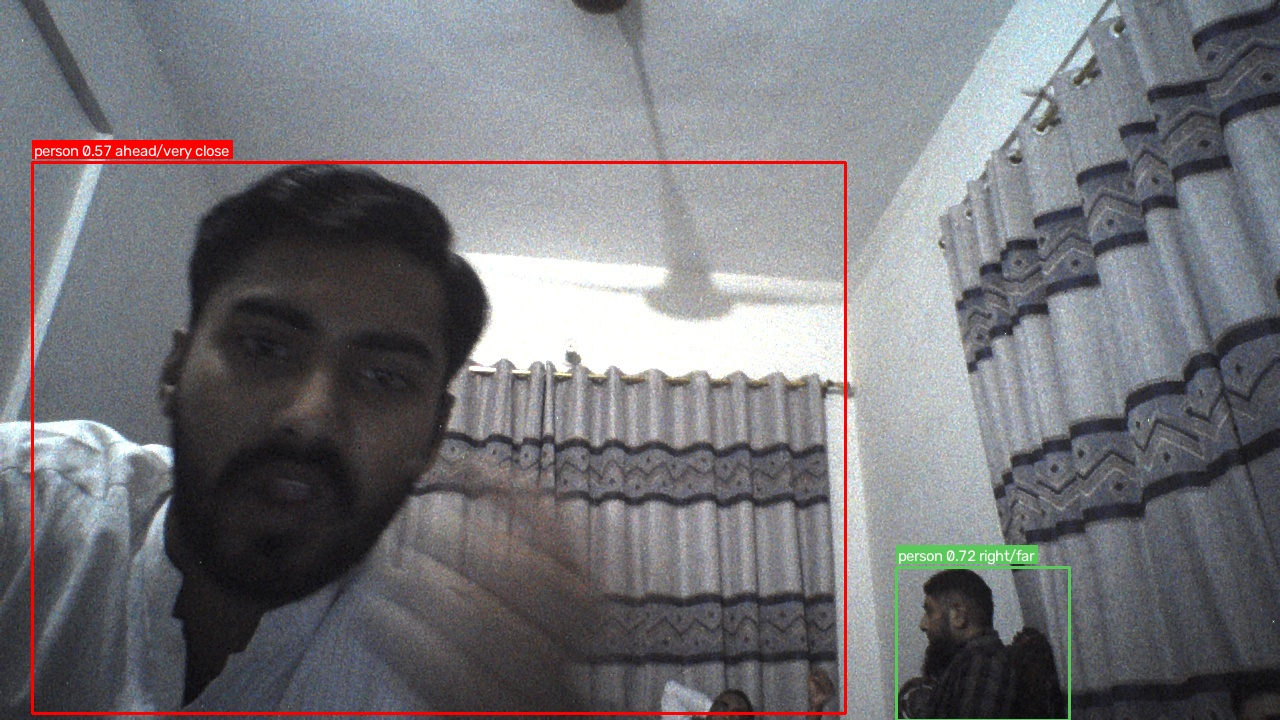

*sample_bottle.jpg*

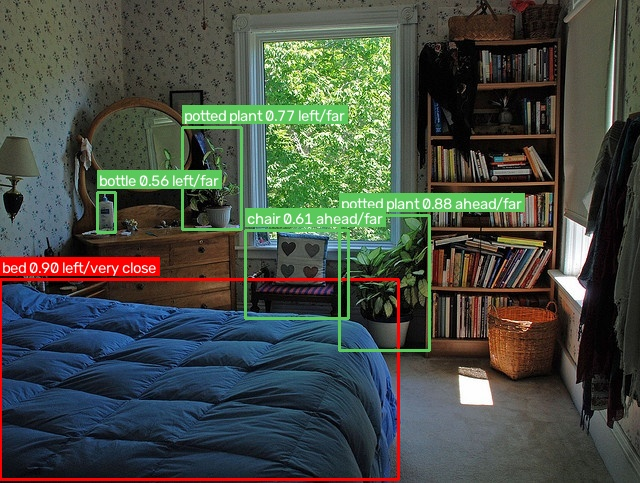

*sample_chair.jpg*

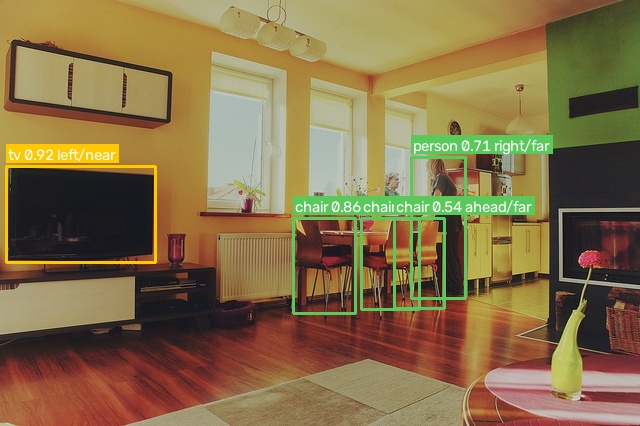

In [8]:
display(Markdown(
    "**What the detector actually saw.** Each box is labelled "
    "`class confidence zone/band` — the same words the app speaks."))
for name in ("cam_01.jpg", "sample_bottle.jpg", "sample_chair.jpg"):
    display(Markdown(f"*{name}*"))
    display(IPyImage(str(EVIDENCE / "eval_position" / name), width=540))


## 6. Interpretation


In [9]:
m50, m95 = o["map50"], o["map5095"]
fast, slow = bench["results"][0], bench["results"][-1]
ratio = slow["avg_ms"] / fast["avg_ms"]
d     = t["detected"]
dirn  = t["direction_correct"]
bandn = t["band_correct"]

display(Markdown(f"""
**Detection.** On this 128-image COCO subset the nano model reaches
**mAP@0.5 = {m50:.4f}** and **mAP@0.5:0.95 = {m95:.4f}**, with precision
{o['precision']:.3f} and recall {o['recall']:.3f}. The gap between the two mAP
numbers ({(m50 - m95):.4f}) is the box-localisation penalty: at IoU 0.5 the
class is usually right, but the exact box edges are imprecise — harmless for
speech output, which only needs "person ahead".

**Which classes work.** The ten most common classes span AP@0.5 from
{min(c['ap50'] for c in top):.3f} to {max(c['ap50'] for c in top):.3f}.
Large, high-contrast, common objects score well; small or unusual ones do not.
Only {o['classes_evaluated']} of the model's {o['classes_in_model']} classes even
occur in this subset, so the average is dominated by what happens to be in it.

**Speed.** {slow['imgsz']} px costs **{ratio:.1f}×** the time of {fast['imgsz']} px
({fast['avg_ms']:.1f} ms → {slow['avg_ms']:.1f} ms). That is far less than the
4× the pixel count implies, because per-call overhead is a large share of the
cheap run. Inference dominates: preprocessing and postprocess are only a couple
of milliseconds. The app therefore detects at roughly {slow['fps']:.1f}
inferences/s while the webcam delivers about 10 FPS — close enough that the
frame-dropping worker thread is what keeps the video from stuttering.

**Positioning.** Of {t['expected']} hand-annotated objects, {d} were detected
(**{d / t['expected']:.0%}**). Given a detection, the positioner is very reliable:
direction correct **{dirn}/{d} ({dirn / d:.0%})** and distance band correct
**{bandn}/{d} ({bandn / d:.0%})**. End-to-end that falls to
{t['both_correct']}/{t['expected']} (**{t['both_correct'] / t['expected']:.0%}**),
and the entire gap is missed detections, not wrong directions.

**Weaknesses — stated plainly.**

- **Small and dim objects get missed.** The single direction error and all
  {len(misses)} misses involve background people, plants or a dining table:
  objects that are small in frame, badly lit, or partly cropped.
- **Distance is not distance.** It is box area divided by frame area. A large
  object far away (a bus filling the frame) reads as "very close", and a small
  object nearby reads as "far". No metric can be quoted honestly here.
- **The subset is tiny.** 128 images versus COCO's official 5,000 means every
  point of mAP is noisy, and {o['classes_in_model'] - o['classes_evaluated']}
  classes never appear at all.
- **No fine-tuning, one scene.** Six of the seven webcam frames are the same
  dim room, so the live-scene results test the close-face and small-background
  cases specifically, not general performance.
"""))



**Detection.** On this 128-image COCO subset the nano model reaches
**mAP@0.5 = 0.6124** and **mAP@0.5:0.95 = 0.4453**, with precision
0.650 and recall 0.542. The gap between the two mAP
numbers (0.1671) is the box-localisation penalty: at IoU 0.5 the
class is usually right, but the exact box edges are imprecise — harmless for
speech output, which only needs "person ahead".

**Which classes work.** The ten most common classes span AP@0.5 from
0.162 to 0.770.
Large, high-contrast, common objects score well; small or unusual ones do not.
Only 71 of the model's 80 classes even
occur in this subset, so the average is dominated by what happens to be in it.

**Speed.** 640 px costs **2.0×** the time of 320 px
(75.6 ms → 148.0 ms). That is far less than the
4× the pixel count implies, because per-call overhead is a large share of the
cheap run. Inference dominates: preprocessing and postprocess are only a couple
of milliseconds. The app therefore detects at roughly 6.8
inferences/s while the webcam delivers about 10 FPS — close enough that the
frame-dropping worker thread is what keeps the video from stuttering.

**Positioning.** Of 38 hand-annotated objects, 27 were detected
(**71%**). Given a detection, the positioner is very reliable:
direction correct **26/27 (96%)** and distance band correct
**27/27 (100%)**. End-to-end that falls to
26/38 (**68%**),
and the entire gap is missed detections, not wrong directions.

**Weaknesses — stated plainly.**

- **Small and dim objects get missed.** The single direction error and all
  11 misses involve background people, plants or a dining table:
  objects that are small in frame, badly lit, or partly cropped.
- **Distance is not distance.** It is box area divided by frame area. A large
  object far away (a bus filling the frame) reads as "very close", and a small
  object nearby reads as "far". No metric can be quoted honestly here.
- **The subset is tiny.** 128 images versus COCO's official 5,000 means every
  point of mAP is noisy, and 9
  classes never appear at all.
- **No fine-tuning, one scene.** Six of the seven webcam frames are the same
  dim room, so the live-scene results test the close-face and small-background
  cases specifically, not general performance.
